In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
model = tf.keras.applications.resnet_v2.ResNet50V2(include_top=True,weights='imagenet')
model.trainable = False
decode_predictions = tf.keras.applications.resnet_v2.decode_predictions

102869336/102869336 [==============================] - 1s 0us/step


In [ ]:
def preprocess(image):
    img = tf.keras.preprocessing.image.load_img(image, target_size=(224, 224))
    img = tf.keras.preprocessing.image.img_to_array(img)
    img = tf.cast(img, tf.float32)
    img = tf.keras.applications.resnet_v2.preprocess_input(img)
    img = img[None,...]
    return img

In [ ]:
img = 'cat-2.JPEG'
img = preprocess(img)

pred = model.predict(img)
lab = decode_predictions(pred,top=1)[0][0][1]
conf = decode_predictions(pred,top=1)[0][0][2]
print(lab)
print(conf*100)
print('Index of label = {}'.format(pred.argmax()))

35363/35363 [==============================] - 0s 0us/step
Persian_cat
99.99812841415405
Index of label = 283


<function matplotlib.pyplot.show(close=None, block=None)>

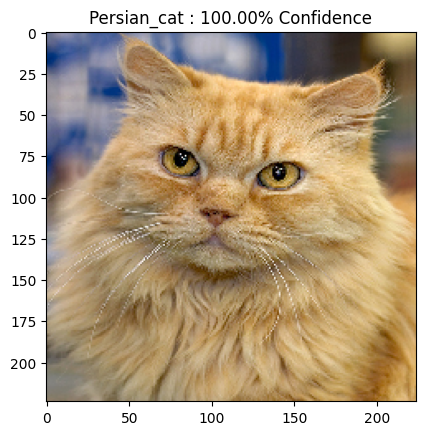

In [ ]:
plt.imshow(tf.keras.preprocessing.image.load_img('cat-2.JPEG', target_size=(224, 224)))
plt.title('{} : {:.2f}% Confidence'.format(lab, conf*100))
plt.show

In [ ]:
loss_object = tf.keras.losses.CategoricalCrossentropy()

def get_gradient(input_image, input_label):
  with tf.GradientTape() as tape:
    tape.watch(input_image)
    prediction = model(input_image)
    loss = loss_object(input_label, prediction)

  # Get the gradients of the loss w.r.t to the input image.
  gradient = tape.gradient(loss, input_image)
  return gradient

def get_momentum(gradient):
  denominator = tf.norm(gradient, ord=1)
  denominator = denominator.numpy()
  momentum = gradient / denominator
  return momentum

In [ ]:
def display_images(image, description):
  # confidence=[]
  pred = model.predict(image)
  lab = decode_predictions(pred,top=1)[0][0][1]
  conf = decode_predictions(pred,top=1)[0][0][2]
  # confidence.append(conf)
  plt.figure()
  plt.imshow(image[0]*0.5+0.5)
  plt.title('{} \n {} : {:.4f}% Confidence'.format(description, lab, conf*100))
  plt.show()
  return conf*100,lab


1/1 [==============================] - 0s 173ms/step


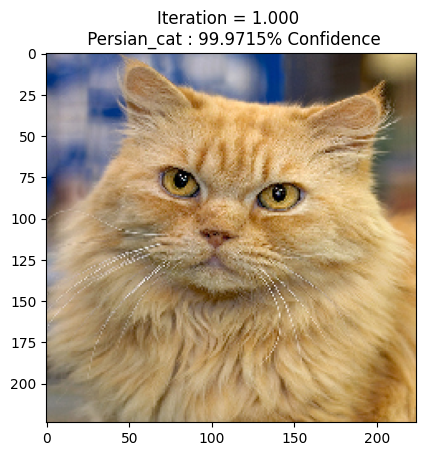

1/1 [==============================] - 0s 189ms/step


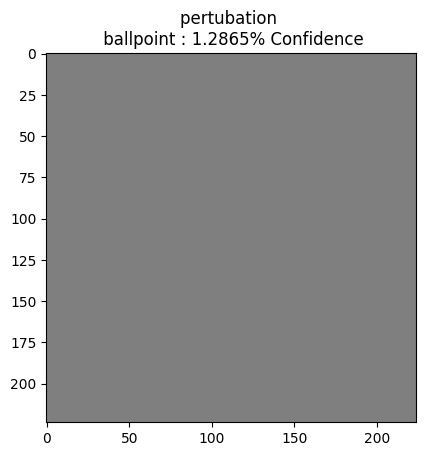

1/1 [==============================] - 0s 168ms/step


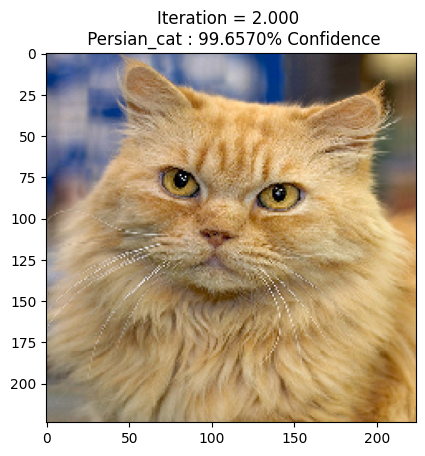

1/1 [==============================] - 0s 175ms/step


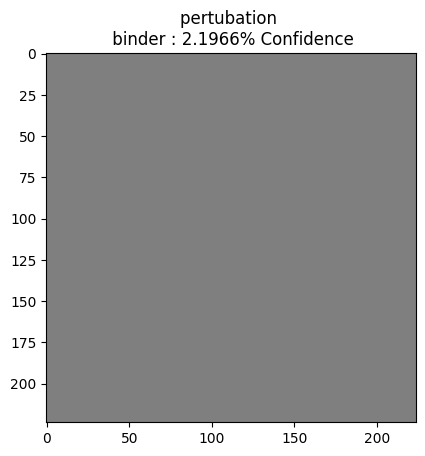

1/1 [==============================] - 0s 190ms/step


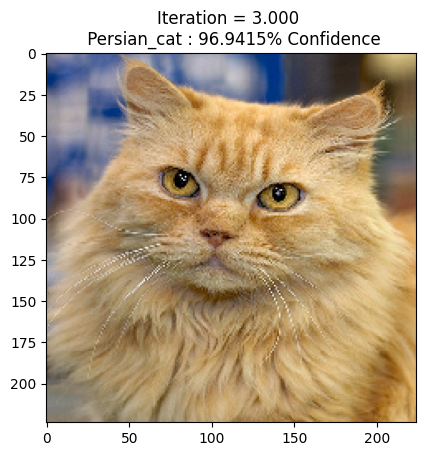

1/1 [==============================] - 0s 176ms/step


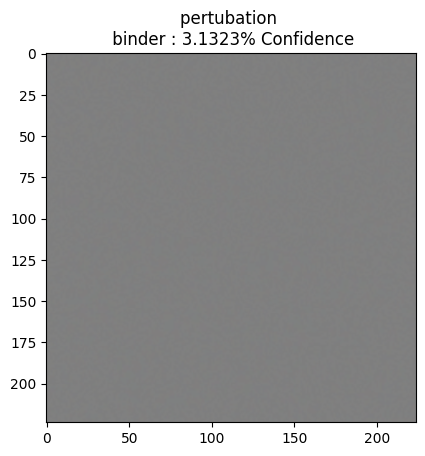

1/1 [==============================] - 0s 293ms/step


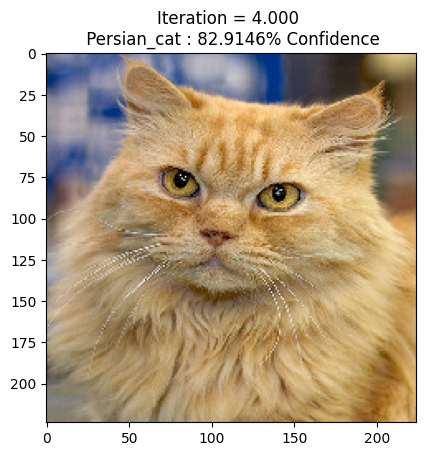

1/1 [==============================] - 0s 279ms/step


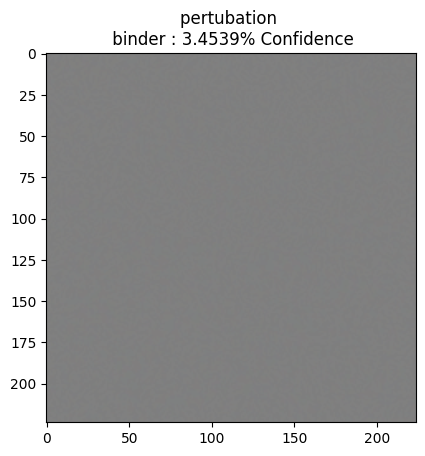

1/1 [==============================] - 0s 177ms/step


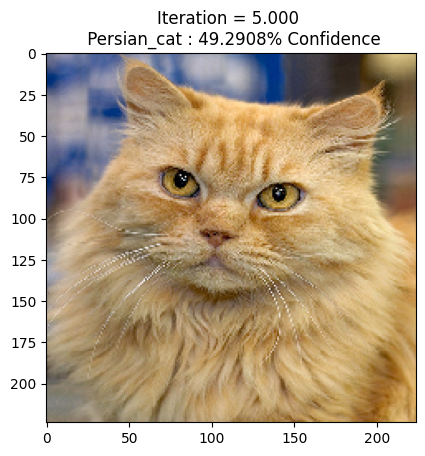

1/1 [==============================] - 0s 175ms/step


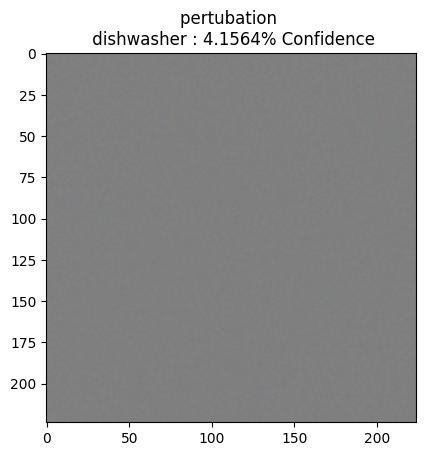

1/1 [==============================] - 0s 183ms/step


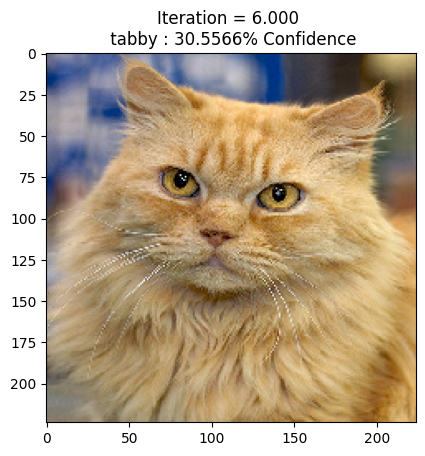

1/1 [==============================] - 0s 176ms/step


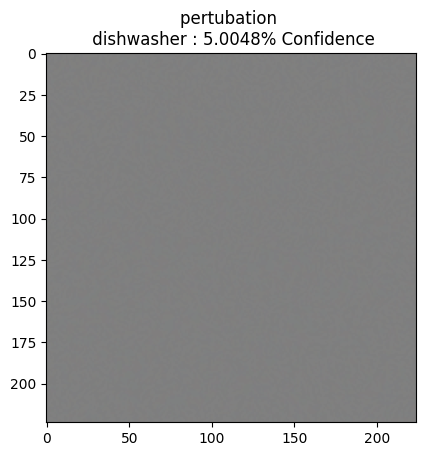

[{'Persian_cat': 99.97147917747498, 'ballpoint': 1.2865344062447548}, {'Persian_cat': 99.65699911117554, 'binder': 2.196582406759262}, {'Persian_cat': 96.941477060318, 'binder': 3.1322818249464035}, {'Persian_cat': 82.91459679603577, 'binder': 3.4538887441158295}, {'Persian_cat': 49.290844798088074, 'dishwasher': 4.156374558806419}, {'tabby': 30.55655062198639, 'dishwasher': 5.004808306694031}]


In [ ]:
adv_x = img
momentum = 0
decay = 1.2
eps = 0.01
t = 6
alpha = eps/t
descriptions = [('Iteration = {:0.3f}'.format(i+1)) for i in range(0,1000)]

ans=[]

for i in range(0,t):
  result={}
  #current prediction
  pred = model.predict(adv_x)

  #getting label of true class
  label_index = pred.argmax()
  label = tf.one_hot(label_index, pred.shape[-1])
  label = tf.reshape(label, (1, pred.shape[-1]))

  #getting momentum update value for t timestamp
  gradient_val = get_gradient(img, label)
  momentum_val = get_momentum(gradient_val[0])

  #updating our momentum for t timestamp
  momentum = decay*momentum + momentum_val

  #getting sign of momentum for t timestamp
  sign = tf.sign(momentum)

  #updating adversarial example
  adv_x = adv_x + (alpha*sign)
  adv_x = tf.clip_by_value(adv_x, -1, 1)

  #displaying final adversarial example
  #if (i==t-1):
  conf1,lab1=display_images(adv_x, descriptions[i])
  conf2,lab2=display_images(adv_x - img, 'pertubation')
  result[lab1]=conf1
  result[lab2]=conf2
  ans.append(result)
print(ans)


In [ ]:
ans

[{'Persian_cat': 99.97147917747498, 'ballpoint': 1.2865344062447548},
 {'Persian_cat': 99.65699911117554, 'binder': 2.196582406759262},
 {'Persian_cat': 96.941477060318, 'binder': 3.1322818249464035},
 {'Persian_cat': 82.91459679603577, 'binder': 3.4538887441158295},
 {'Persian_cat': 49.290844798088074, 'dishwasher': 4.156374558806419},
 {'tabby': 30.55655062198639, 'dishwasher': 5.004808306694031}]

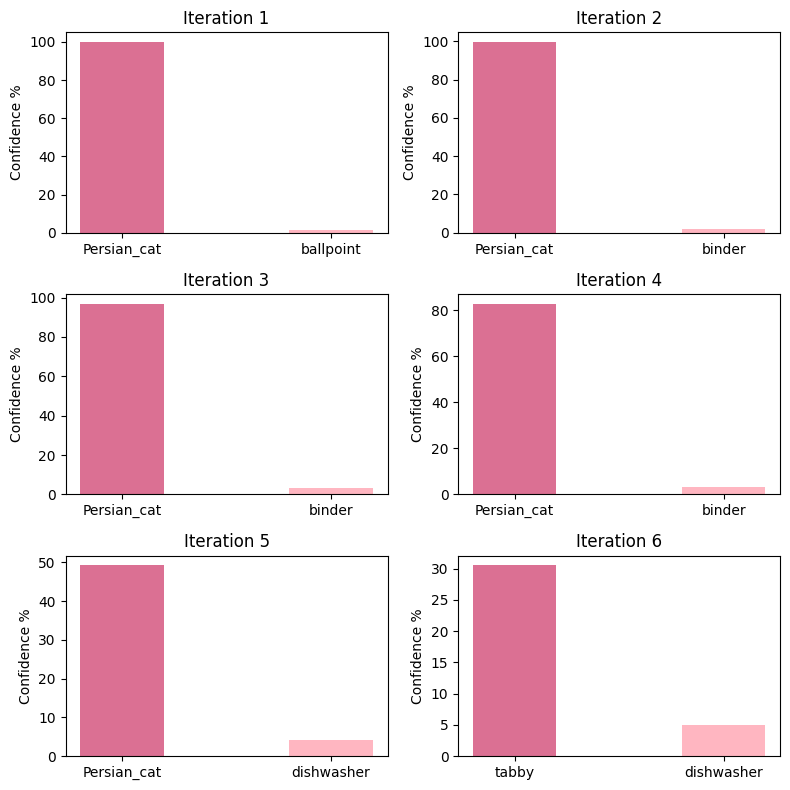

In [ ]:
# Create a 2x2 figure
fig, axs = plt.subplots(3, 2, figsize=(8, 8))

# Define colors
colors = ['palevioletred', 'lightpink']

# Plot data from each dictionary
for i, data_dict in enumerate(ans):
    row = i // 2
    col = i % 2
    ax = axs[row, col]

    labels = list(data_dict.keys())
    values = list(data_dict.values())

    # Define a width for the bars
    width = 0.4

    x = np.arange(len(labels))

    ax.bar(x, values, width=width, color=colors)

    ax.set_title(f'Iteration {i + 1}')
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylabel('Confidence %')

# Adjust layout
plt.tight_layout()

# Show the combined figure
plt.show()
